# Com aprèn un model: una recta, iteració a iteració

**Optativa d'Aprenentatge automàtic — DAM/DAW 2n**

`MA_01` acabava amb aquesta frase: **un model entrenat és un vector de números, i predir és
multiplicar.** Vam agafar els pesos d'un model ja entrenat, vam fer `X @ w + b` a mà i ens va
sortir el mateix que a scikit-learn. Però vam deixar una pregunta oberta: **d'on surten aquells
números?**

Aquest quadern la respon amb el model més senzill que existeix: una recta.

$$\hat{y} = w\,x + b$$

Dos números, $w$ (el pendent) i $b$ (on talla l'eix vertical). Entrenar el model és trobar els
dos números que fan que la recta passi el més a prop possible dels punts. I ho farem com ho fa
un model de debò: començant amb una recta qualsevol i **corregint-la una mica a cada pas**, fins
que ja no millora.

El pla:

1. Les dades: una recta que es veu a ull.
2. Prova-ho tu: mou la recta amb els dits.
3. Com es mesura «a prop»: l'error quadràtic mitjà.
4. El paisatge de l'error.
5. Cap a on baixa: la derivada.
6. El gradient, i la transposada de `MA_01` tornant a aparèixer.
7. El bucle d'entrenament.
8. La recta aprenent, en moviment.
9. La taxa d'aprenentatge: massa poc, bé, massa.
10. Comparació amb scikit-learn.
11. El parany de les escales.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris()
x = iris.data[:, 2]     # llargada del pètal (cm): el que coneixem
y = iris.data[:, 3]     # amplada del pètal (cm): el que volem predir

print("Flors:", len(x))
print("x (llargada) va de", x.min(), "a", x.max(), "cm")
print("y (amplada)  va de", y.min(), "a", y.max(), "cm")

Flors: 150
x (llargada) va de 1.0 a 6.9 cm
y (amplada)  va de 0.1 a 2.5 cm


## 1. Les dades

La pregunta és: **si sé la llargada d'un pètal, puc endevinar-ne l'amplada?** Abans de cap
fórmula, mirem-ho.

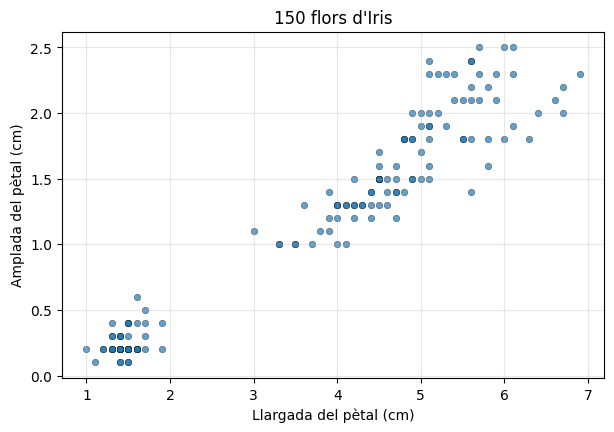

In [2]:
plt.figure(figsize=(7, 4.5))
plt.scatter(x, y, s=22, alpha=0.7, edgecolor="k", linewidth=0.3)
plt.xlabel("Llargada del pètal (cm)")
plt.ylabel("Amplada del pètal (cm)")
plt.title("150 flors d'Iris")
plt.grid(alpha=0.3)
plt.show()

Els punts fan una franja estreta que puja: pètal més llarg, pètal més ample. Una recta hi
encaixarà bé. El que no sabem és **quina** recta, és a dir, quins $w$ i $b$.

## 2. Prova-ho tu: mou la recta

Dos controls, $w$ i $b$. Les línies grises verticals són els **residus**: la distància vertical
entre cada flor i la recta, és a dir, quant s'equivoca el model en aquella flor. A dalt hi ha un
número que resumeix tots els errors (l'apartat 3 explica com es calcula). **Busca la recta que el
deixi més petit.**

In [3]:
from ipywidgets import interact, FloatSlider

def mse(w, b):
    return np.mean((w * x + b - y) ** 2)

def dibuixa_recta(w=0.0, b=0.0):
    pred = w * x + b
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    ax.vlines(x, y, pred, color="gray", alpha=0.35, linewidth=0.8)
    ax.scatter(x, y, s=20, alpha=0.7, edgecolor="k", linewidth=0.3)
    xs = np.array([0, 7.5])
    ax.plot(xs, w * xs + b, color="tab:red", linewidth=2.2)
    ax.set_xlim(0, 7.5)
    ax.set_ylim(-0.5, 3.2)
    ax.set_xlabel("Llargada del pètal (cm)")
    ax.set_ylabel("Amplada del pètal (cm)")
    ax.set_title(f"w = {w:.2f}   b = {b:.2f}   →   error (MSE) = {mse(w, b):.4f}")
    ax.grid(alpha=0.3)
    plt.show()

interact(dibuixa_recta,
         w=FloatSlider(min=-0.5, max=1.0, step=0.01, value=0.0, description="w"),
         b=FloatSlider(min=-2.0, max=2.0, step=0.05, value=0.0, description="b"));

interactive(children=(FloatSlider(value=0.0, description='w', max=1.0, min=-0.5, step=0.01), FloatSlider(value…

Si heu jugat una estona, haureu notat dues coses. La primera: **hi ha una recta millor que les
altres**, i quan us hi acosteu l'error baixa cada cop menys. La segona: el que feu és **moure un
control, mirar si l'error baixa, i seguir en aquella direcció**. Això és exactament el descens
de gradient. L'únic que farem és que, en comptes de provar a cegues, l'ordinador **calculi** cap
a on ha de moure cada control.

## 3. Com es mesura «a prop»: l'error quadràtic mitjà

Per a cada flor $i$, el residu és $\hat{y}_i - y_i$: el que diu la recta menys el que és de
veritat. Els elevem al quadrat (així els negatius no compensen els positius, i un error gran
pesa molt més que un de petit) i en fem la mitjana:

$$\text{MSE}(w, b) = \frac{1}{n}\sum_{i=1}^{n}\left(w\,x_i + b - y_i\right)^2$$

En NumPy és una línia: la mateixa `mse` que fa servir el control de l'apartat 2.

In [4]:
print(f"Recta plana (w=0, b=0):   MSE = {mse(0, 0):.4f}")
print(f"Recta y = x (w=1, b=0):   MSE = {mse(1, 0):.4f}")
print(f"Recta y = 0.4x (w=0.4):   MSE = {mse(0.4, 0):.4f}")

Recta plana (w=0, b=0):   MSE = 2.0155
Recta y = x (w=1, b=0):   MSE = 7.6455
Recta y = 0.4x (w=0.4):   MSE = 0.1352


La recta plana s'equivoca de mitjana en $\sqrt{2{,}02} \approx 1{,}4$ cm, que és molt per a
pètals que fan com a molt 2,5 cm d'ample. La recta $y = x$ encara és pitjor: dobla l'amplada de
tots els pètals llargs. Amb $w = 0{,}4$ ja som a prop. El que busquem és el **$w$ i el $b$ que
fan el MSE mínim**. Entrenar vol dir exactament això: **minimitzar una funció d'error.**

## 4. El paisatge de l'error

El MSE depèn de dos números, $w$ i $b$. Podem calcular-lo en una graella de valors i pintar-lo
com un mapa topogràfic: cada corba uneix els punts amb el mateix error, com les corbes de nivell
d'un mapa de muntanya. El que busquem és **el fons de la vall**.

Millor punt de la graella: w = 0.412, b = -0.349, MSE = 0.04211


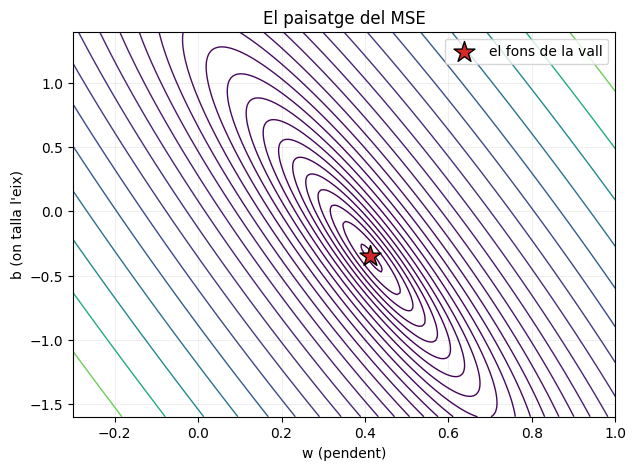

In [5]:
w_vals = np.linspace(-0.3, 1.0, 200)
b_vals = np.linspace(-1.6, 1.4, 200)
W, B = np.meshgrid(w_vals, b_vals)
# MSE a cada punt de la graella, sense bucles: x[:, None, None] fa que cada flor
# es combini amb tots els (w, b) alhora.
E = np.mean((W * x[:, None, None] + B - y[:, None, None]) ** 2, axis=0)

i_min, j_min = np.unravel_index(np.argmin(E), E.shape)
print(f"Millor punt de la graella: w = {W[i_min, j_min]:.3f}, b = {B[i_min, j_min]:.3f}, "
      f"MSE = {E[i_min, j_min]:.5f}")

plt.figure(figsize=(7, 5))
nivells = np.geomspace(E.min() * 1.05, E.max(), 25)
plt.contour(W, B, E, levels=nivells, cmap="viridis", linewidths=1)
plt.scatter(W[i_min, j_min], B[i_min, j_min], marker="*", s=250, color="tab:red",
            edgecolor="k", zorder=3, label="el fons de la vall")
plt.xlabel("w (pendent)")
plt.ylabel("b (on talla l'eix)")
plt.title("El paisatge del MSE")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Dues observacions que tornaran a sortir:

- La vall té **un sol fons**. Això passa sempre amb la regressió lineal i el MSE, i és una
  sort: comencis on comencis, si baixes acabes al mateix lloc.
- La vall és **molt allargada i estreta**, inclinada en diagonal. Moure $w$ una mica canvia molt
  l'error; moure $b$ el canvia poc. Aquesta forma tindrà conseqüències a l'apartat 8 i a l'11.

Amb 2 números, la graella de 200 × 200 = 40.000 càlculs ha funcionat. Amb 30 pesos caldrien
$200^{30}$, que és un número de 70 xifres. Per això no es fa així: cal una manera de **saber
cap a on baixa** sense mirar tot el mapa.

## 5. Cap a on baixa: la derivada

Imagineu que esteu a la muntanya amb boira i no veieu res. Per baixar, toqueu el terra amb el
peu i mireu cap a on fa pendent. Això és una **derivada**: el pendent de la funció al punt on
sou.

Es pot calcular sense saber cap fórmula: mous $w$ una mica, $h$, i mires quant ha canviat
l'error.

$$\frac{\partial\,\text{MSE}}{\partial w} \approx \frac{\text{MSE}(w + h,\, b) - \text{MSE}(w - h,\, b)}{2h}$$

El símbol $\partial$ es llegeix «derivada parcial» i vol dir: derivada respecte de $w$ deixant
$b$ quiet.

In [6]:
h = 1e-6
w0, b0 = 0.0, 0.0

pendent_w = (mse(w0 + h, b0) - mse(w0 - h, b0)) / (2 * h)
pendent_b = (mse(w0, b0 + h) - mse(w0, b0 - h)) / (2 * h)
print(f"A (w=0, b=0):  pendent respecte de w = {pendent_w:.4f}")
print(f"               pendent respecte de b = {pendent_b:.4f}")

A (w=0, b=0):  pendent respecte de w = -11.5881
               pendent respecte de b = -2.3987


Tots dos pendents són **negatius**: si augmentem $w$ o $b$, l'error baixa. Té sentit, la recta
plana és massa baixa. I el de $w$ és molt més gran en valor absolut que el de $b$, que és la
vall estreta de l'apartat 4 dita amb números.

La regla per baixar surt sola: **moure's en sentit contrari al pendent**. Si el pendent és
negatiu, augmentar; si és positiu, disminuir. Dibuixem-ho tallant el paisatge per $b = 0$: la
recta vermella és la tangent, i el seu pendent és el número d'adalt.

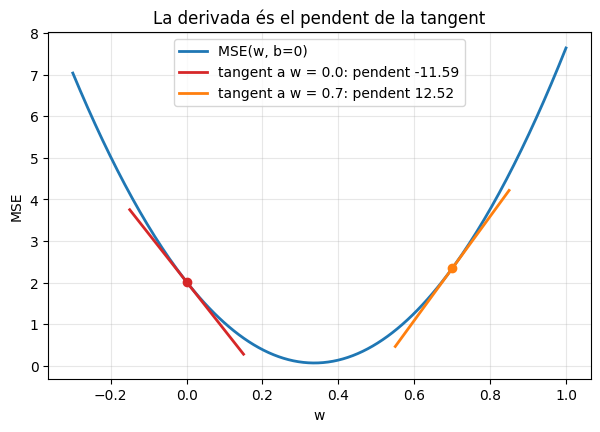

In [7]:
ws = np.linspace(-0.3, 1.0, 200)
plt.figure(figsize=(7, 4.5))
plt.plot(ws, [mse(w, 0) for w in ws], linewidth=2, label="MSE(w, b=0)")
for w_punt, color in [(0.0, "tab:red"), (0.7, "tab:orange")]:
    p = (mse(w_punt + h, 0) - mse(w_punt - h, 0)) / (2 * h)
    tram = np.linspace(w_punt - 0.15, w_punt + 0.15, 2)
    plt.plot(tram, mse(w_punt, 0) + p * (tram - w_punt), color=color, linewidth=2,
             label=f"tangent a w = {w_punt}: pendent {p:.2f}")
    plt.scatter([w_punt], [mse(w_punt, 0)], color=color, zorder=3)
plt.xlabel("w")
plt.ylabel("MSE")
plt.title("La derivada és el pendent de la tangent")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

A $w = 0$ el pendent és negatiu: cal anar cap a la dreta. A $w = 0{,}7$ és positiu: ens hem
passat, cal tornar enrere. Al fons de la corba el pendent és zero, i allà el mètode s'atura sol.

## 6. El gradient

El **gradient** és simplement els dos pendents posats en un vector:

$$\nabla \text{MSE} = \left(\frac{\partial\,\text{MSE}}{\partial w},\ \frac{\partial\,\text{MSE}}{\partial b}\right)$$

Per al MSE es poden treure amb llapis (regla de la cadena: la derivada de $u^2$ és $2u$, i la
de $w\,x_i + b$ respecte de $w$ és $x_i$). Ho donem fet:

$$\frac{\partial\,\text{MSE}}{\partial w} = \frac{2}{n}\sum_{i} (\hat{y}_i - y_i)\,x_i
\qquad
\frac{\partial\,\text{MSE}}{\partial b} = \frac{2}{n}\sum_{i} (\hat{y}_i - y_i)$$

Llegides en paraules: **el residu de cada flor, multiplicat per la seva $x$, i fet la mitjana.**
Les flors on la recta s'equivoca molt empenyen fort; les que encerten no empenyen gens. Abans de
fiar-nos-en, ho comprovem contra el càlcul numèric de l'apartat 5.

In [8]:
def gradient(w, b):
    residu = w * x + b - y
    grad_w = 2 * np.mean(residu * x)
    grad_b = 2 * np.mean(residu)
    return grad_w, grad_b

for w_p, b_p in [(0.0, 0.0), (0.7, 0.3), (0.4, -0.3)]:
    analitic = gradient(w_p, b_p)
    numeric = ((mse(w_p + h, b_p) - mse(w_p - h, b_p)) / (2 * h),
               (mse(w_p, b_p + h) - mse(w_p, b_p - h)) / (2 * h))
    print(f"(w={w_p}, b={b_p})  fórmula: ({analitic[0]:+.6f}, {analitic[1]:+.6f})"
          f"   numèric: ({numeric[0]:+.6f}, {numeric[1]:+.6f})")

(w=0.0, b=0.0)  fórmula: (-11.588133, -2.398667)   numèric: (-11.588133, -2.398667)
(w=0.7, b=0.3)  fórmula: (+14.771960, +3.462533)   numèric: (+14.771960, +3.462533)
(w=0.4, b=-0.3)  fórmula: (-0.068480, +0.007733)   numèric: (-0.068480, +0.007733)


Coincideixen fins al sisè decimal. Aquesta comprovació té nom, **gradient checking**, i és el
que es fa sempre que s'escriu un gradient a mà: si no coincideix, la fórmula està malament.

**La transposada de `MA_01`, tornant a aparèixer.** Si en lloc d'una columna en tenim
moltes, $x$ passa a ser la matriu $X$ i $w$ un vector. La fórmula és la mateixa escrita amb
matrius:

$$\nabla_w \text{MSE} = \frac{2}{n}\,X^{\top}(Xw + b - y)$$

`X.T @ residu` fa, per a cada columna, «el residu de cada flor per la seva $x$, sumat». És
l'apartat 8 de `MA_01` fent feina de veritat. Ho comprovem amb la nostra $x$ posada com a
matriu d'una columna:

In [9]:
Xm = x.reshape(-1, 1)             # (150,) -> (150, 1): una matriu d'una columna
w_vec = np.array([0.7])
residu = Xm @ w_vec + 0.3 - y
print("Amb matrius:", 2 / len(y) * (Xm.T @ residu))
print("Amb la fórmula d'abans:", gradient(0.7, 0.3)[0])

Amb matrius: [14.77196]
Amb la fórmula d'abans: 14.771959999999996


## 7. El bucle d'entrenament

Ja tenim totes les peces. Entrenar és repetir això:

$$w \leftarrow w - \eta\,\frac{\partial\,\text{MSE}}{\partial w}
\qquad
b \leftarrow b - \eta\,\frac{\partial\,\text{MSE}}{\partial b}$$

La fletxa vol dir «substitueix». El signe menys és el «contrari del pendent». I $\eta$ (la
lletra grega *eta*) és la **taxa d'aprenentatge**: com de llarga és cada passa. És l'únic número
que triem nosaltres; de moment, $\eta = 0{,}02$.

In [10]:
def entrena(eta, iteracions, w=0.0, b=0.0):
    # Descens de gradient. Retorna l'historial de (w, b, MSE) a cada iteració.
    historial = [(w, b, mse(w, b))]
    for _ in range(iteracions):
        grad_w, grad_b = gradient(w, b)
        w = w - eta * grad_w
        b = b - eta * grad_b
        historial.append((w, b, mse(w, b)))
    return np.array(historial)

hist = entrena(eta=0.02, iteracions=2000)

print(f"{'iteració':>9} {'w':>9} {'b':>9} {'MSE':>10}")
for it in [0, 1, 2, 5, 10, 50, 100, 500, 1000, 2000]:
    w_i, b_i, e_i = hist[it]
    print(f"{it:>9} {w_i:>9.4f} {b_i:>9.4f} {e_i:>10.5f}")

 iteració         w         b        MSE
        0    0.0000    0.0000    2.01553
        1    0.2318    0.0480    0.22548
        2    0.2967    0.0592    0.08658
        5    0.3229    0.0558    0.07365
       10    0.3265    0.0417    0.07154
       50    0.3480   -0.0557    0.05906
      100    0.3677   -0.1452    0.05060
      500    0.4127   -0.3492    0.04210
     1000    0.4157   -0.3626    0.04207
     2000    0.4158   -0.3631    0.04207


Hi ha dues fases, i no les hem programades:

- **Les primeres 5 iteracions**: l'error cau de 2,02 a 0,07. El pendent $w$ salta de 0 a 0,32.
  És la part fàcil: girar la recta fins que segueixi la franja.
- **De la 10 a la 1.000**: l'error baixa a poc a poc de 0,07 a 0,042, mentre $b$ baixa lentament
  de +0,04 a −0,36 i $w$ va ajustant-se a 0,42. És el fons de la vall estreta de l'apartat 4: el
  terreny és gairebé pla en aquella direcció i les passes són curtes.

A partir de la 1.000 ja no canvia res al quart decimal. El model està entrenat: $w = 0{,}4158$ i
$b = -0{,}3631$. **Dos números, i aquesta és la resposta a la pregunta de `MA_01`.**

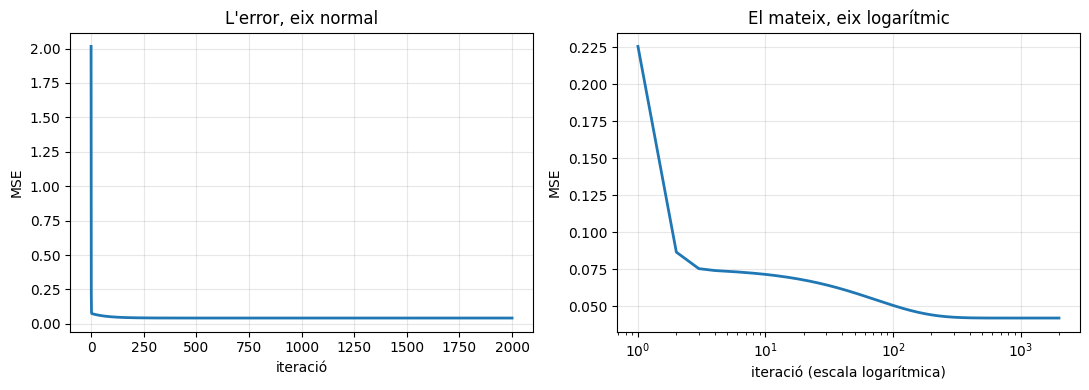

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(hist[:, 2], linewidth=2)
ax1.set_xlabel("iteració")
ax1.set_ylabel("MSE")
ax1.set_title("L'error, eix normal")
ax1.grid(alpha=0.3)
ax2.semilogx(np.arange(1, len(hist)), hist[1:, 2], linewidth=2)
ax2.set_xlabel("iteració (escala logarítmica)")
ax2.set_ylabel("MSE")
ax2.set_title("El mateix, eix logarítmic")
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

El gràfic de l'esquerra sembla dir que després de la iteració 10 no passa res. El de la dreta, amb
l'eix horitzontal logarítmic, ensenya que continua baixant fins a la 1.000. Les corbes d'error
d'entrenament es miren gairebé sempre així.

## 8. La recta aprenent, en moviment

Tres vistes de la mateixa cosa, sincronitzades: la recta sobre les flors, el punt $(w, b)$
baixant pel paisatge, i l'error. Premeu el botó de reproduir. Els fotogrames no estan repartits
per igual: n'hi ha molts al principi, on tot passa de pressa, i pocs al final.

In [12]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fotogrames = np.unique(np.geomspace(1, 2000, 30).astype(int))
fotogrames = np.concatenate([[0], fotogrames])

fig, (axr, axp, axe) = plt.subplots(1, 3, figsize=(12, 3.6), dpi=55)
xs = np.array([0, 7.5])

def fotograma(k):
    it = fotogrames[k]
    w_i, b_i, e_i = hist[it]
    for ax in (axr, axp, axe):
        ax.clear()
    # la recta
    axr.scatter(x, y, s=12, alpha=0.6, edgecolor="k", linewidth=0.2)
    axr.plot(xs, w_i * xs + b_i, color="tab:red", linewidth=2.2)
    axr.set_xlim(0, 7.5)
    axr.set_ylim(-0.5, 3.2)
    axr.set_title(f"iteració {it}")
    axr.set_xlabel("llargada (cm)")
    axr.set_ylabel("amplada (cm)")
    # el paisatge
    axp.contour(W, B, E, levels=nivells, cmap="viridis", linewidths=0.8)
    axp.plot(hist[:it + 1, 0], hist[:it + 1, 1], color="tab:red", linewidth=1.5)
    axp.scatter([w_i], [b_i], color="tab:red", s=40, zorder=3)
    axp.set_xlabel("w")
    axp.set_ylabel("b")
    axp.set_title(f"w = {w_i:.3f}   b = {b_i:.3f}")
    # l'error
    axe.semilogx(np.arange(1, len(hist)), hist[1:, 2], color="lightgray")
    axe.semilogx(np.arange(1, it + 1), hist[1:it + 1, 2], color="tab:blue", linewidth=2)
    axe.set_ylim(0, 0.9)
    axe.set_xlabel("iteració")
    axe.set_title(f"MSE = {e_i:.4f}")
    fig.tight_layout()

animacio = FuncAnimation(fig, fotograma, frames=len(fotogrames), interval=180)
plt.close(fig)
HTML(animacio.to_jshtml())

Mireu el panell del mig. El punt no va recte cap a l'estrella: primer **baixa de cop cap al
fons de la vall** (la recta gira) i després **avança arran del fons**, lentament, cap a
l'estrella (la recta baixa). Això és el que fa la forma allargada de la vall: el gradient
apunta cap a on la pendent és més forta, que no és cap on és el mínim.

Si ho preferiu sense animació, aquí podeu anar a qualsevol iteració:

In [13]:
from ipywidgets import IntSlider

def mostra_iteracio(it=0):
    w_i, b_i, e_i = hist[it]
    fig, (axr, axp) = plt.subplots(1, 2, figsize=(11, 4))
    axr.scatter(x, y, s=15, alpha=0.6, edgecolor="k", linewidth=0.2)
    axr.plot(xs, w_i * xs + b_i, color="tab:red", linewidth=2.2)
    axr.set_xlim(0, 7.5)
    axr.set_ylim(-0.5, 3.2)
    axr.set_title(f"iteració {it}:  MSE = {e_i:.4f}")
    axp.contour(W, B, E, levels=nivells, cmap="viridis", linewidths=0.8)
    axp.plot(hist[:it + 1, 0], hist[:it + 1, 1], color="tab:red", linewidth=1.5)
    axp.scatter([w_i], [b_i], color="tab:red", s=40, zorder=3)
    axp.set_title(f"w = {w_i:.4f}   b = {b_i:.4f}")
    axp.set_xlabel("w")
    axp.set_ylabel("b")
    plt.tight_layout()
    plt.show()

interact(mostra_iteracio, it=IntSlider(min=0, max=2000, step=1, value=0, description="iteració"));

interactive(children=(IntSlider(value=0, description='iteració', max=2000), Output()), _dom_classes=('widget-i…

## 9. La taxa d'aprenentatge: massa poc, bé, massa

$\eta$ diu com de llarga és cada passa. Mou el control i mira què passa amb els primers 60
passos:

- amb $\eta$ petit el punt baixa amb seguretat però tarda;
- cap a $0{,}05$ comença a **fer ziga-zaga** d'una paret de la vall a l'altra, i tot i així arriba;
- a partir de $0{,}056$ aproximadament cada salt el porta més amunt que l'anterior, i l'error
  **explota**.

In [14]:
def prova_eta(eta=0.02):
    h_eta = entrena(eta=eta, iteracions=60)
    fig, (axp, axe) = plt.subplots(1, 2, figsize=(11, 4))
    axp.contour(W, B, E, levels=nivells, cmap="viridis", linewidths=0.8)
    axp.plot(h_eta[:, 0], h_eta[:, 1], "o-", color="tab:red", markersize=3, linewidth=1)
    axp.set_xlim(w_vals[0], w_vals[-1])
    axp.set_ylim(b_vals[0], b_vals[-1])
    axp.set_xlabel("w")
    axp.set_ylabel("b")
    axp.set_title(f"η = {eta}: 60 passos")
    with np.errstate(over="ignore", invalid="ignore"):
        axe.semilogy(h_eta[:, 2], "o-", markersize=3)
    axe.set_xlabel("iteració")
    axe.set_ylabel("MSE (escala log)")
    axe.set_title(f"MSE final: {h_eta[-1, 2]:.4g}")
    axe.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

interact(prova_eta, eta=FloatSlider(min=0.002, max=0.06, step=0.002, value=0.02,
                                     readout_format=".3f", description="η"));

interactive(children=(FloatSlider(value=0.02, description='η', max=0.06, min=0.002, readout_format='.3f', step…

In [15]:
for eta in [0.005, 0.02, 0.05, 0.06]:
    with np.errstate(over="ignore", invalid="ignore"):
        h_eta = entrena(eta=eta, iteracions=1000)
    print(f"η = {eta:<6}  MSE després de 10: {h_eta[10, 2]:<12.5g} després de 1000: {h_eta[-1, 2]:.5g}")

η = 0.005   MSE després de 10: 0.11098      després de 1000: 0.043159
η = 0.02    MSE després de 10: 0.071541     després de 1000: 0.042067
η = 0.05    MSE després de 10: 0.091111     després de 1000: 0.042067
η = 0.06    MSE després de 10: 41.617       després de 1000: 2.3729e+133


No hi ha cap manera de saber la $\eta$ bona abans de provar. A la pràctica es comença amb un
valor i es mira la corba d'error: si puja, es divideix per 10; si baixa massa a poc a poc, es
multiplica. **Quan un entrenament «no funciona», la primera sospitosa és sempre la $\eta$.**

## 10. Comparació amb scikit-learn

`LinearRegression` resol el mateix problema. Si el nostre bucle és correcte, ha de donar els
mateixos dos números.

In [16]:
from sklearn.linear_model import LinearRegression

model = LinearRegression().fit(x.reshape(-1, 1), y)
w_nostre, b_nostre, e_nostre = hist[-1]

print(f"{'':>14} {'w':>10} {'b':>10} {'MSE':>10}")
print(f"{'el nostre':>14} {w_nostre:>10.6f} {b_nostre:>10.6f} {e_nostre:>10.6f}")
print(f"{'scikit-learn':>14} {model.coef_[0]:>10.6f} {model.intercept_:>10.6f} "
      f"{mse(model.coef_[0], model.intercept_):>10.6f}")

                        w          b        MSE
     el nostre   0.415755  -0.363075   0.042067
  scikit-learn   0.415755  -0.363076   0.042067


Els mateixos números. Una diferència important, però: `LinearRegression` **no fa descens de
gradient**. Per a la regressió lineal amb MSE hi ha una fórmula tancada que dona el mínim en un
sol càlcul. El descens de gradient l'hem fet servir perquè **és el mètode que funciona per a
tots els models**, també els que no tenen fórmula: la regressió logística, les xarxes neuronals.
Una xarxa amb milions de pesos s'entrena amb el bucle de l'apartat 7, sense canviar-hi res
més que la funció d'error i el gradient.

## 11. El parany de les escales

Ara un experiment que sembla innocent. Mesurem la llargada en **mil·límetres** en lloc de
centímetres: multipliquem $x$ per 10. Les flors són les mateixes, la recta bona és la mateixa
(només que el pendent passa a ser 10 vegades més petit). Tornem a entrenar amb la mateixa
$\eta = 0{,}02$.

In [17]:
x_cm = x.copy()
x = x_cm * 10            # ara en mm: les funcions mse() i gradient() fan servir aquesta x

with np.errstate(over="ignore", invalid="ignore"):
    h_mm = entrena(eta=0.02, iteracions=10)
for it in [0, 1, 2, 5, 10]:
    print(f"iteració {it:>2}:  MSE = {h_mm[it, 2]:.4g}")

x = x_cm                 # tornem als cm

iteració  0:  MSE = 2.016
iteració  1:  MSE = 8990
iteració  2:  MSE = 4.145e+07
iteració  5:  MSE = 4.064e+18
iteració 10:  MSE = 8.472e+36


Explota. El problema és que el gradient respecte de $w$ es multiplica per $x$, i ara les $x$
són 10 vegades més grans: les passes en $w$ són 10 vegades més llargues i surten de la vall.
Caldria una $\eta$ 100 vegades més petita, i llavors $b$ no es mouria mai.

La solució habitual és **posar totes les columnes a la mateixa escala abans d'entrenar**: restar
la mitjana i dividir per la desviació típica. És el que fa `StandardScaler`. Mirem què passa amb
la $x$ estandarditzada:

In [18]:
x_std = (x_cm - x_cm.mean()) / x_cm.std()
x = x_std

h_std = entrena(eta=0.1, iteracions=100)
for it in [0, 10, 20, 50, 100]:
    print(f"iteració {it:>3}:  MSE = {h_std[it, 2]:.6f}")

x = x_cm                 # tornem als cm

iteració   0:  MSE = 2.015533
iteració  10:  MSE = 0.064820
iteració  20:  MSE = 0.042330
iteració  50:  MSE = 0.042067
iteració 100:  MSE = 0.042067


**El mateix error mínim, 0,042067, en 50 iteracions en lloc de 1.000.** Amb la $x$ centrada,
la vall deixa de ser allargada i es torna rodona, el gradient apunta directament al fons, i
es pot fer servir una $\eta$ més gran sense que exploti.

Això no és un detall d'aquest quadern. Les escales tornaran a ser un parany a **k veïns** (on la
columna més gran decideix tota sola la distància) i a les **xarxes neuronals** (on les dades
sense escalar fan que l'entrenament no arrenqui). Recordeu el número: de 1.000 a 50.

## Pràctica

### Exercici 1. El teu propi descens, amb una altra parella de columnes

Fes servir la **llargada del sèpal** (`iris.data[:, 0]`) per predir la **llargada del pètal**
(`iris.data[:, 2]`). Escriu tu la funció d'error, el gradient i el bucle (pots copiar l'estructura
dels apartats 3, 6 i 7). Comprova el gradient contra el numèric en un punt qualsevol abans
d'entrenar. Troba una $\eta$ que convergeixi i compara el resultat amb `LinearRegression`.

In [19]:
# Exercici 1
# 1. xs1 = iris.data[:, 0]; ys1 = iris.data[:, 2]
# 2. Defineix mse1(w, b) i gradient1(w, b) amb xs1 i ys1.
# 3. Comprova gradient1 contra el càlcul numèric a (w=0.5, b=0.5).
# 4. Entrena amb diverses eta: quina és la més gran que no explota?
# 5. Compara w i b amb LinearRegression().fit(xs1.reshape(-1, 1), ys1).

### Exercici 2. Escalar o no escalar

Repeteix l'exercici 1 amb la $x$ estandarditzada. Fes una taula amb, per a cada cas (sense
escalar i escalada), la $\eta$ més gran que funciona i quantes iteracions calen perquè el MSE
quedi a menys d'un 1 % del mínim. Explica en dues frases per què surt el que surt.

**Compte:** amb la $x$ escalada, els $w$ i $b$ que trobes no són els de la recta en cm. Busca
com es desfà el canvi per comparar-los amb `LinearRegression`.

In [20]:
# Exercici 2
# 1. xs1_std = (xs1 - xs1.mean()) / xs1.std()
# 2. Entrena amb diverses eta i guarda, per a cada una, a quina iteració el MSE
#    baixa per sota de 1.01 * MSE_minim.
# 3. Construeix un pd.DataFrame amb els resultats i imprimeix-lo.
# 4. Pista per desfer l'escala: w*xs1_std + b = (w/std)*xs1 + (b - w*mean/std)

### Exercici 3. Dues columnes alhora, amb matrius

Predeix l'amplada del pètal fent servir **dues** columnes: la llargada del pètal i la llargada
del sèpal. Ara $w$ és un vector de 2 components i la predicció és `X @ w + b`, com a `MA_01`.
Fes servir la fórmula amb la transposada de l'apartat 6 per al gradient. Estandarditza les dues
columnes abans. Compara amb `LinearRegression` i digues si afegir el sèpal ha baixat l'error.

In [21]:
# Exercici 3
# 1. X2 = iris.data[:, [2, 0]]; estandarditza cada columna (axis=0).
# 2. w = np.zeros(2); b = 0.0
# 3. Bucle: residu = X2 @ w + b - y
#           grad_w = 2 / len(y) * (X2.T @ residu)
#           grad_b = 2 * residu.mean()
# 4. Compara amb LinearRegression().fit(X2, y) i amb el MSE d'una sola columna.

## Resum

- **Entrenar és minimitzar una funció d'error.** Per a la regressió, el MSE: la mitjana dels
  residus al quadrat.
- La **derivada** és el pendent de l'error en el punt on som. El **gradient** és el vector dels
  pendents, un per pes.
- **Descens de gradient**: `w = w - eta * grad_w`, repetit. Al començament canvia molt, a prop del
  mínim gairebé res, i s'atura sol perquè el gradient s'anul·la.
- El gradient escrit a mà **es comprova** sempre contra el numèric (*gradient checking*).
- Amb moltes columnes, el gradient és `2 / n * X.T @ residu`: la transposada de `MA_01`.
- La **taxa d'aprenentatge** $\eta$ decideix si baixa lent, baixa bé o explota. Es tria provant.
- **Escalar les dades** canvia la forma de la vall: de 1.000 iteracions a 50 per arribar al mateix
  error.
- Amb això queda resposta la pregunta de `MA_01`: els pesos d'un model surten d'aquest bucle. A
  la regressió logística (`ML_04`) i a `MA_02` es fa el mateix amb una altra funció d'error.